In [44]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [96]:
img = cv2.imread("img.jpg",cv2.IMREAD_GRAYSCALE)

## Question 01

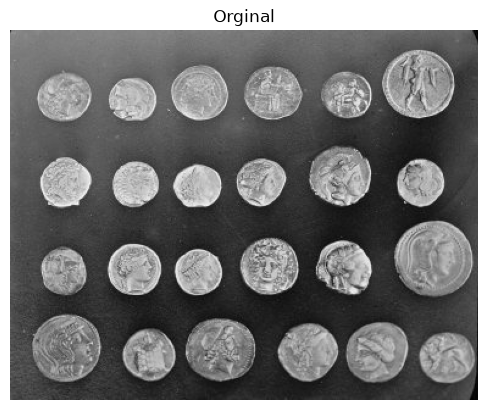

In [97]:
plt.title("Orginal")
plt.imshow(img, cmap = "gray")
plt.axis("off")
plt.show()

In [117]:
img2 = img + 60
img2 = np.clip(img2,0,255)

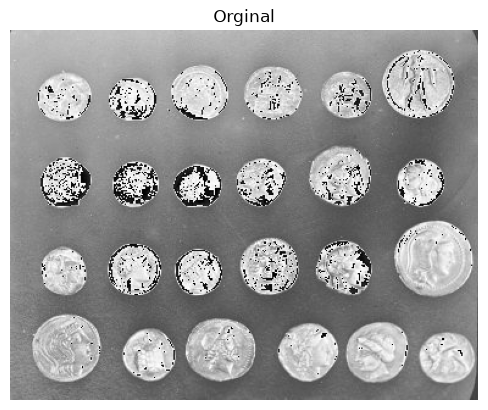

In [118]:
plt.title("Orginal")
plt.imshow(img2, cmap = "gray")
plt.axis("off")
plt.show()

In [121]:
norm = img / 255.0
img3 = np.power(norm,0.4) * 255
img3 = np.clip(img3,0,255)
img3 = img3.astype(np.uint8)

img4 = np.power(norm,1.0) * 255
img4 = np.clip(img4,0,255)
img4 = img4.astype(np.uint8)

img5 = np.power(norm,2.0) * 255
img5 = np.clip(img5,0,255)
img5 = img5.astype(np.uint8)

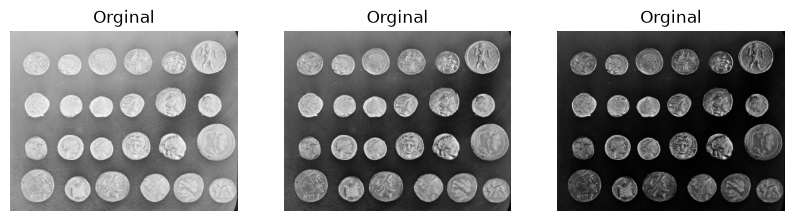

In [125]:
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.title("Orginal")
plt.imshow(img3, cmap = "gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Orginal")
plt.imshow(img4, cmap = "gray")
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Orginal")
plt.imshow(img5, cmap = "gray")
plt.axis("off")
plt.show()

## Question 02

In [126]:
img = cv2.imread("img.jpg",cv2.IMREAD_GRAYSCALE)

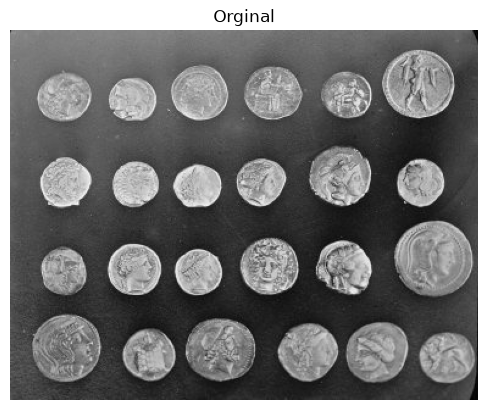

In [127]:
plt.title("Orginal")
plt.imshow(img, cmap = "gray")
plt.axis("off")
plt.show()

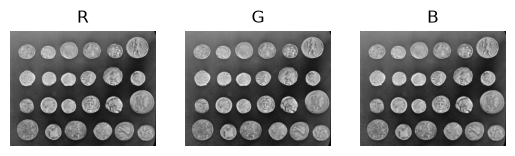

In [129]:
plt.subplot(1,3,1)
plt.title("R")
plt.imshow(img, cmap = "gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("G")
plt.imshow(img, cmap = "gray")
plt.axis("off")

plt.subplot(1,3,3)
plt.title("B")
plt.imshow(img, cmap = "gray")
plt.axis("off")

plt.show()

## Question 03

In [46]:
hist,_=np.histogram(img,256,(0,256))

<BarContainer object of 256 artists>

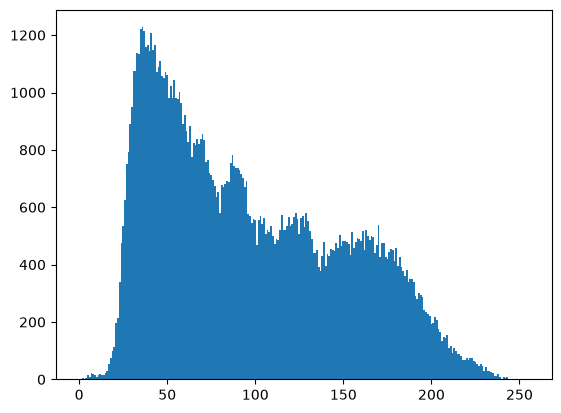

In [47]:
plt.bar(range(0,256),hist,1)

In [48]:
print("MAX              :  ", np.argmax(hist))
print("Pixel intensity  :  ", hist.max())

MAX              :   36
Pixel intensity  :   1227


In [49]:
cdf = hist.cumsum()
cdf_normalized = cdf * 255 / cdf[-1]

In [50]:
equ_manual = np.interp(img.flatten(), np.arange(256), cdf_normalized)
equ_manual = equ_manual.reshape(img.shape)
equ_manual = equ_manual.astype(np.uint8)

In [51]:
equ_cv2 = cv2.equalizeHist(img)

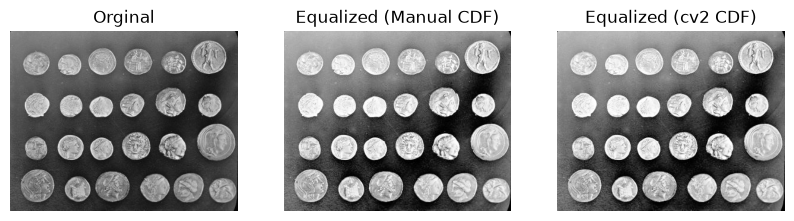

In [52]:
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.title("Orginal")
plt.imshow(img, cmap = "gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Equalized (Manual CDF)")
plt.imshow(equ_manual, cmap = "gray")
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Equalized (cv2 CDF)")
plt.imshow(equ_cv2, cmap = "gray")
plt.axis("off")

plt.show()

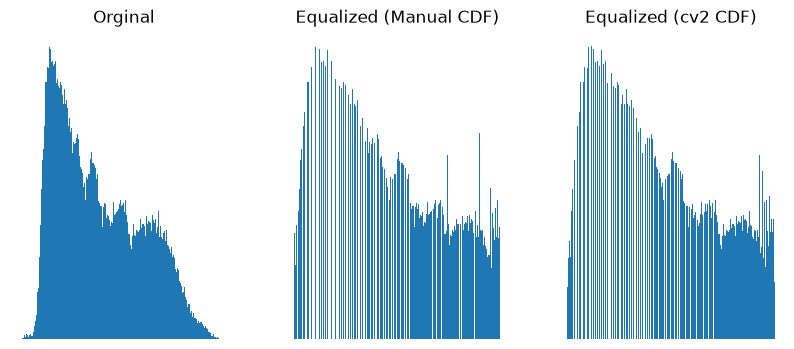

In [53]:
plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.title("Orginal")
hist,_=np.histogram(img,256,(0,256))
plt.bar(range(0,256),hist,1)
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Equalized (Manual CDF)")
hist,_=np.histogram(equ_manual,256,(0,256))
plt.bar(range(0,256),hist,1)
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Equalized (cv2 CDF)")
hist,_=np.histogram(equ_cv2,256,(0,256))
plt.bar(range(0,256),hist,1)
plt.axis("off")

plt.show()

## Question 04

In [54]:
noise = np.random.normal(0,25,img.shape)
gaussian_noise = img.astype(np.float32) + noise
c = np.clip(gaussian_noise,0,255)
gaussian_noise = gaussian_noise.astype(np.uint8)

In [58]:
sp_noice = img.copy()
num_pixels =  img.size
num_salt = int(0.015 * num_pixels)
num_pepper = int(0.015 * num_pixels)

In [59]:
salt_rows = np.random.randint(0, img.shape[0], num_salt)
salt_cols = np.random.randint(0, img.shape[1], num_salt)
sp_noice[salt_rows, salt_cols] = 255

In [60]:
pepper_rows = np.random.randint(0, img.shape[0], num_pepper)
pepper_cols = np.random.randint(0, img.shape[1], num_pepper)
sp_noice[pepper_rows, pepper_cols] = 0

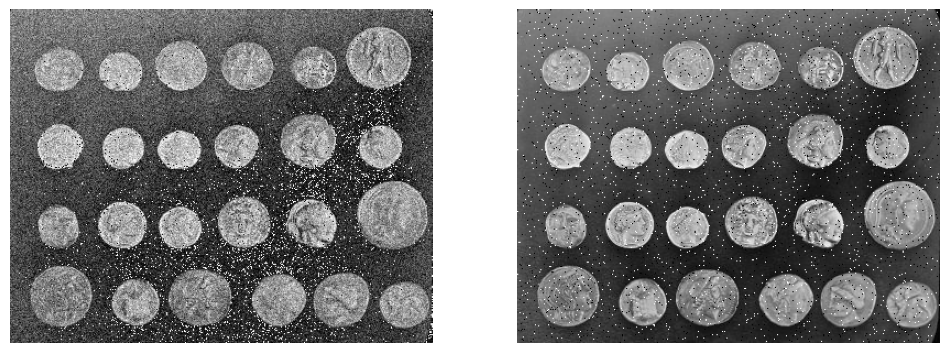

In [70]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(gaussian_noise, cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(sp_noice, cmap="gray")
plt.axis("off")

plt.show()

In [67]:
mean= cv2.blur(gaussian_noise, (5, 5))
gaussian = cv2.GaussianBlur(gaussian_noise, (5, 5), sigmaX=1.5)
median = cv2.medianBlur(sp_noice, 5)

In [68]:
mean2 = cv2.blur(sp_noice, (5, 5))
gaussian2 = cv2.GaussianBlur(sp_noice, (5, 5), sigmaX=1.5)
median2 = cv2.medianBlur(sp_noice, 5)

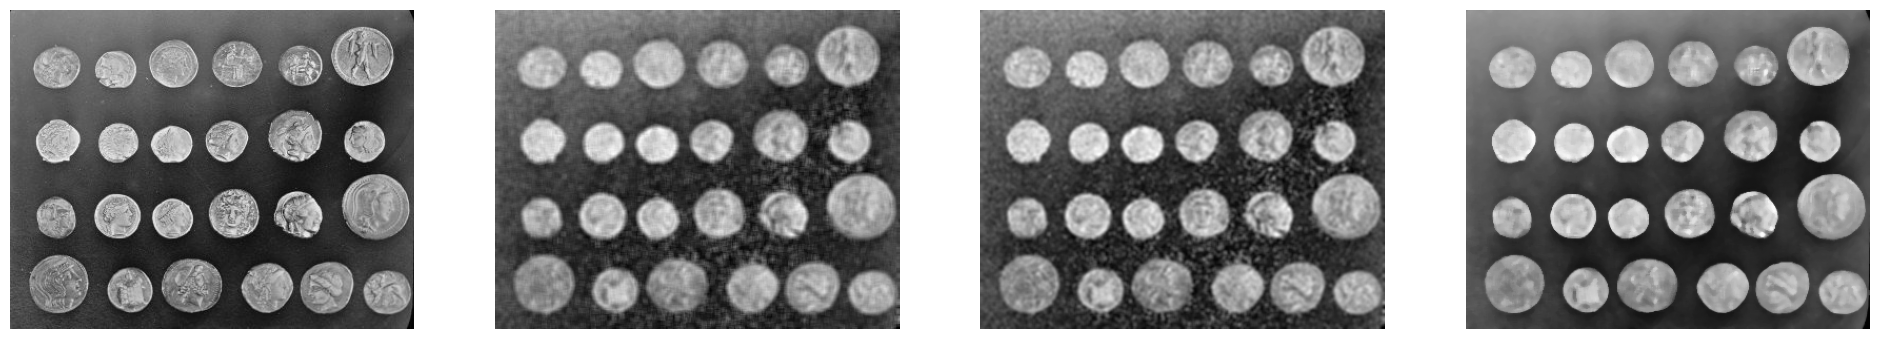

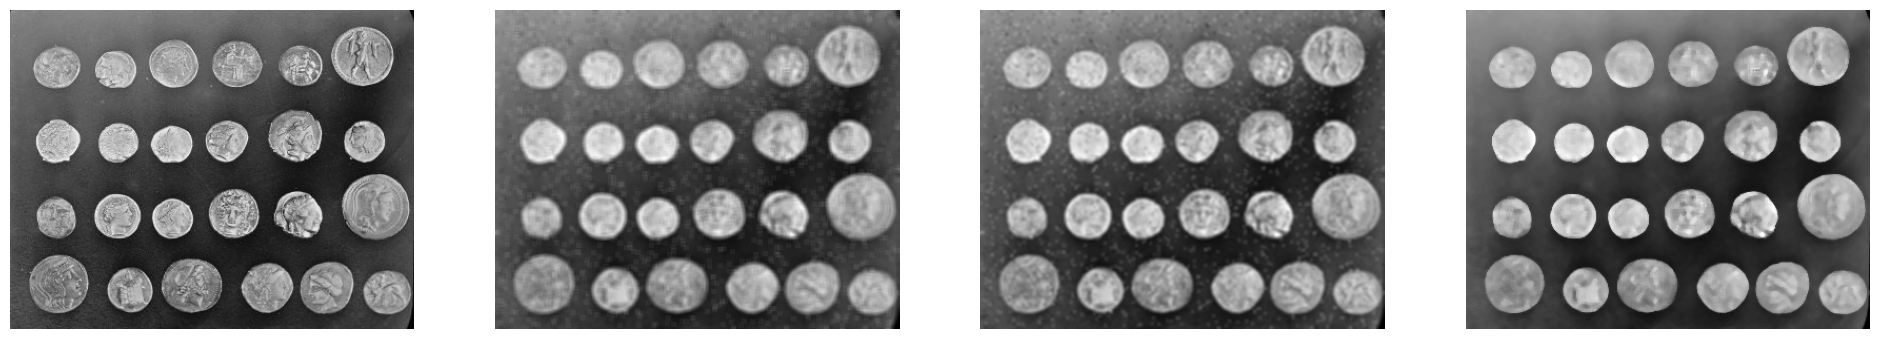

In [73]:
plt.figure(figsize=(24,10))

plt.subplot(1,4,1)
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(mean, cmap="gray")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(gaussian, cmap="gray")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(median, cmap="gray")
plt.axis("off")

plt.show()




plt.figure(figsize=(24,10))

plt.subplot(1,4,1)
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(mean2, cmap="gray")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(gaussian2, cmap="gray")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(median2, cmap="gray")
plt.axis("off")

plt.show()

## Question 05

In [78]:
lap_kernel = np.array([
    [0, 1, 0],
    [1,-4, 1],
    [0, 1, 0]], dtype=np.float32)

In [79]:
lap = cv2.filter2D(img.astype(np.float32), -1, lap_kernel)
lap_display = cv2.convertScaleAbs(lap)

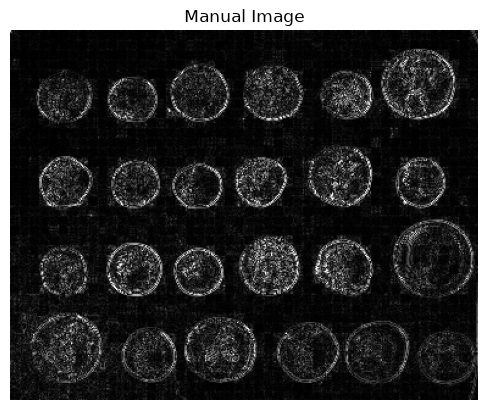

In [81]:
plt.imshow(lap_display, cmap="gray")
plt.title("Manual Image")
plt.axis("off")
plt.show()

In [83]:
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)

sobel_man = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel_man)

In [84]:
sharpening_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]], dtype = np.float32)

In [85]:
sharpened =cv2.filter2D(img, -1, sharpening_kernel)

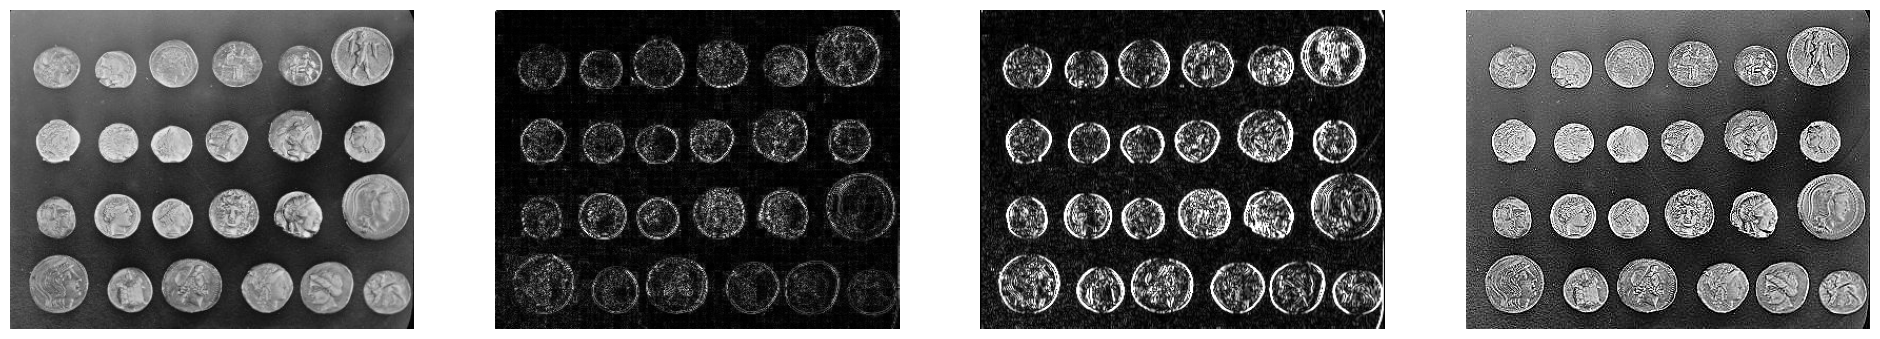

In [86]:
plt.figure(figsize=(24,10))

plt.subplot(1,4,1)
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(lap_display, cmap="gray")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(sobel, cmap="gray")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(sharpened, cmap="gray")
plt.axis("off")

plt.show()